# Exploratory analysis and validation diagnostics

In [1]:
# Imports and project path
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.dates import DateFormatter, HourLocator
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent))
from src.asof import load_data
from src.config import ARTIFACTS, CLASS_LAYOUTS, CORE, DATA, DRIVER_FEATURES, FOLDS, ROOT, SPIKE_FEATURES, TRAIN_CUTOFF
from src.features import all_origins, attach_labels, build_features
from src.models import fit_all, in_bucket, p50_contributions

FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
SUMMARY = {}

In [2]:
# Chart style shared by every figure
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "figure.dpi": 130, "savefig.dpi": 170,
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.7,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2, "legend.frameon": False,
})


# Save a finished figure into the docs folder
def save(figure, name):
    figure.tight_layout()
    figure.savefig(FIGURES / name, bbox_inches="tight")
    plt.show()

In [3]:
# Load only values usable at the training cut-off and build the analysis table
values, usable = load_data()
known = values.where(usable <= TRAIN_CUTOFF)
table = known[known["fi_imbalance_price"].notna()].copy()
table["spread"] = table["fi_imbalance_price"] - table["fi_spot_price"]
table["high"] = table["spread"] > 50
table["low"] = table["spread"] < -50
table["up"] = table["fi_mfrr_direction"] == 1
local_time = table.index.tz_convert("Europe/Helsinki")
table["month"] = local_time.strftime("%Y-%m")
table["hour"] = table["cal_hour_local"].astype(int)
table["weekend"] = table["cal_weekday_local"] >= 5
assert table.index.max() <= pd.Timestamp("2026-10-04T19:45:00Z")
SUMMARY["rows"] = int(len(table))
SUMMARY["last_label"] = str(table.index.max())

## 1. How the price is formed

In [4]:
# Measure the pricing mechanism in each direction
up_rows, down_rows, none_rows = table[table["fi_mfrr_direction"] == 1], table[table["fi_mfrr_direction"] == -1], table[table["fi_mfrr_direction"] == 0]
SUMMARY["mechanism"] = {
    "up_rows": len(up_rows), "down_rows": len(down_rows), "none_rows": len(none_rows),
    "corr_up_price": round(up_rows["fi_imbalance_price"].corr(up_rows["fi_mfrr_up_price"]), 3),
    "corr_down_price": round(down_rows["fi_imbalance_price"].corr(down_rows["fi_mfrr_down_price"]), 3),
    "up_spread_nonnegative": round(float((up_rows["spread"] >= 0).mean()), 3),
    "down_spread_nonpositive": round(float((down_rows["spread"] <= 0).mean()), 3),
    "none_equals_spot": int((none_rows["spread"].abs() < 1e-6).sum()),
    "median_spread_up": round(float(up_rows["spread"].median()), 1), "median_spread_down": round(float(down_rows["spread"].median()), 1),
    "high_given_up": round(float(up_rows["high"].mean()), 3), "high_given_down": round(float(down_rows["high"].mean()), 3),
    "low_given_down": round(float(down_rows["low"].mean()), 3), "low_given_up": round(float(up_rows["low"].mean()), 3),
    "negative_price_share": round(float((table["fi_imbalance_price"] < 0).mean()), 3),
    "negative_spot_share": round(float((table["fi_spot_price"] < 0).mean()), 3),
    "spread_q01_q99": [round(float(x), 1) for x in table["spread"].quantile([.01, .99])],
    "price_min_max": [round(float(table["fi_imbalance_price"].min()), 1), round(float(table["fi_imbalance_price"].max()), 1)],
}
print(json.dumps(SUMMARY["mechanism"], indent=1))

{
 "up_rows": 4221,
 "down_rows": 7851,
 "none_rows": 20,
 "corr_up_price": 0.993,
 "corr_down_price": 0.91,
 "up_spread_nonnegative": 0.902,
 "down_spread_nonpositive": 0.969,
 "none_equals_spot": 20,
 "median_spread_up": 25.1,
 "median_spread_down": -17.0,
 "high_given_up": 0.255,
 "high_given_down": 0.001,
 "low_given_down": 0.11,
 "low_given_up": 0.004,
 "negative_price_share": 0.296,
 "negative_spot_share": 0.008,
 "spread_q01_q99": [
  -117.4,
  149.0
 ],
 "price_min_max": [
  -115.0,
  4000.0
 ]
}


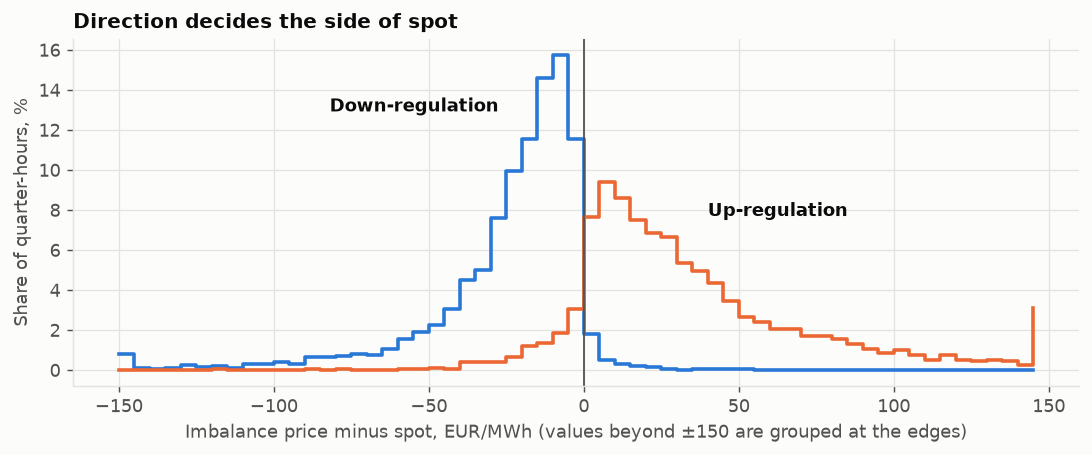

In [5]:
# Chart the spread distribution by direction
figure, axis = plt.subplots(figsize=(8.5, 3.6))
bins = np.arange(-150, 152, 5)
for rows, colour, label, x_text in [(down_rows, BLUE, "Down-regulation", -82), (up_rows, ORANGE, "Up-regulation", 40)]:
    density, edges = np.histogram(rows["spread"].clip(-150, 150), bins=bins)
    share = 100 * density / len(rows)
    axis.step(edges[:-1], share, where="post", color=colour)
    axis.text(x_text, share.max() * 0.82, label, color=INK, fontweight="bold")
axis.axvline(0, color=MUTED, linewidth=1)
axis.set_title("Direction decides the side of spot")
axis.set_xlabel("Imbalance price minus spot, EUR/MWh (values beyond ±150 are grouped at the edges)")
axis.set_ylabel("Share of quarter-hours, %")
save(figure, "fig1_spread_by_direction.png")

**What we learnt**

- Direction decides which side of spot the price lands on. In down-regulation the price sits just below spot (median −17.0 EUR/MWh). In up-regulation it is above spot (median +25.1) with a long upper tail.
- With no dominant direction (20 quarter-hours), the price equals spot.
- Up-regulation causes 25.5% high spikes. Down-regulation causes 11.0% low spikes.

**Why this helps against the baseline**

The baseline repeats the last known price for all 40 steps. We start from the published spot price of each quarter-hour and predict only the gap. That follows the real pricing rule, while the baseline ignores that spot changes through the day.

## 2. Regime shift

In [6]:
# Summarise each month
monthly = table.groupby("month").agg(
    quarter_hours=("spread", "size"), mean_abs_spread=("spread", lambda s: s.abs().mean()),
    high_spike_pct=("high", lambda s: 100 * s.mean()), low_spike_pct=("low", lambda s: 100 * s.mean()), up_pct=("up", lambda s: 100 * s.mean()),
).round(1)
SUMMARY["monthly"] = monthly.reset_index().to_dict("records")
display(monthly)

,quarter_hours,mean_abs_spread,high_spike_pct,low_spike_pct,up_pct
month,,,,,
2026-06,2880,32.4,12.0,7.4,38.3
2026-07,2976,18.0,2.7,0.5,30.6
2026-08,2976,29.6,10.5,6.6,38.8
2026-09,2880,45.0,10.1,14.9,33.3
2026-10,380,40.1,15.0,6.3,25.0


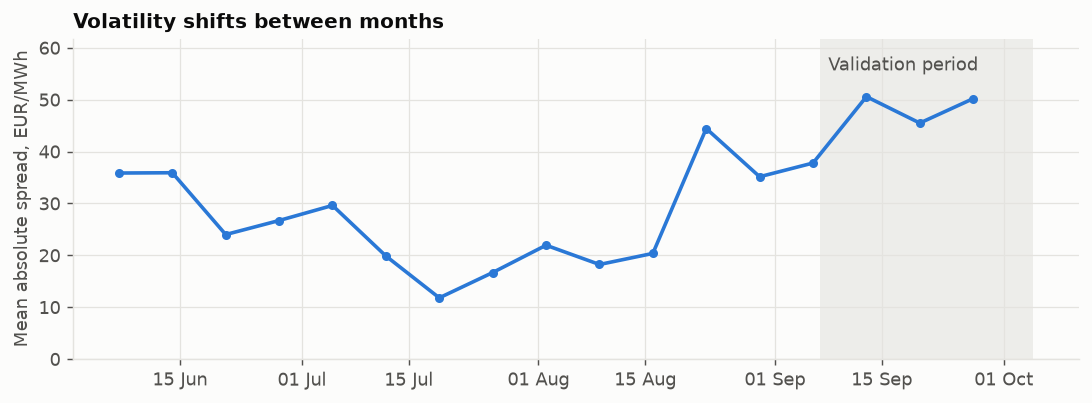

In [7]:
# Chart weekly volatility over the training period
weekly = table["spread"].abs().resample("W").mean().iloc[1:-1]
figure, axis = plt.subplots(figsize=(8.5, 3.2))
axis.plot(weekly.index, weekly.values, color=BLUE, marker="o", markersize=4)
axis.axvspan(pd.Timestamp("2026-09-06T21:00Z"), pd.Timestamp("2026-10-04T21:00Z"), color=GRID, alpha=0.6, linewidth=0)
axis.text(pd.Timestamp("2026-09-08T00:00Z"), weekly.max() * 1.1, "Validation period", color=MUTED)
axis.set_title("Volatility shifts between months")
axis.set_ylabel("Mean absolute spread, EUR/MWh")
axis.set_ylim(0, weekly.max() * 1.22)
axis.xaxis.set_major_formatter(DateFormatter("%d %b"))
save(figure, "fig2_weekly_volatility.png")

**What we learnt**

- Volatility changes a lot over time. Weekly average gaps fell to about 12 EUR/MWh in July and rose to about 50 in the validation period.
- A model trained mostly on calm summer weeks will underestimate risk in a volatile autumn.

**What we did about it**

- Small, strongly regularised models, so they don't memorise one period.
- Volatility features only in the spike models.
- A fixed 1.25 widening of the `p10`–`p90` range.
- Testing on three time periods instead of one.

## 3. Time patterns

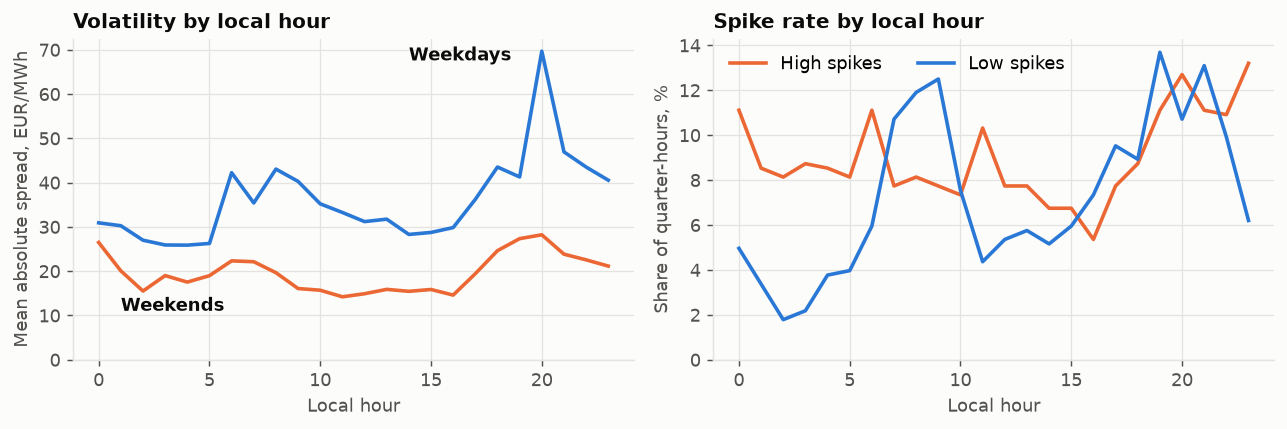

{'weekday_peak_hour': 20, 'weekday_peak': 69.7, 'weekday_mean': 36.1, 'weekend_mean': 19.6, 'weekday_high_pct': 10.9, 'weekend_high_pct': 4.0, 'peak_high_hour': 23, 'peak_high_pct': 13.2, 'peak_low_hour': 19, 'peak_low_pct': 13.7}


In [8]:
# Chart volatility and spike rates by local hour
profile = table.groupby(["weekend", "hour"])["spread"].apply(lambda s: s.abs().mean()).unstack(0)
hourly = table.groupby("hour")[["high", "low"]].mean() * 100
figure, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(profile.index, profile[False], color=BLUE)
axes[0].plot(profile.index, profile[True], color=ORANGE)
axes[0].text(profile[False].idxmax() - 6, profile[False].max() * 0.97, "Weekdays", color=INK, fontweight="bold")
axes[0].text(1, profile[True].iloc[1:6].max() * 0.55, "Weekends", color=INK, fontweight="bold")
axes[0].set_title("Volatility by local hour")
axes[0].set_xlabel("Local hour")
axes[0].set_ylabel("Mean absolute spread, EUR/MWh")
axes[0].set_ylim(bottom=0)
axes[1].plot(hourly.index, hourly["high"], color=ORANGE, label="High spikes")
axes[1].plot(hourly.index, hourly["low"], color=BLUE, label="Low spikes")
axes[1].legend(loc="upper left", ncols=2)
axes[1].set_title("Spike rate by local hour")
axes[1].set_xlabel("Local hour")
axes[1].set_ylabel("Share of quarter-hours, %")
axes[1].set_ylim(bottom=0)
save(figure, "fig3_time_patterns.png")
SUMMARY["time"] = {
    "weekday_peak_hour": int(profile[False].idxmax()), "weekday_peak": round(float(profile[False].max()), 1),
    "weekday_mean": round(float(table.loc[~table["weekend"], "spread"].abs().mean()), 1), "weekend_mean": round(float(table.loc[table["weekend"], "spread"].abs().mean()), 1),
    "weekday_high_pct": round(float(100 * table.loc[~table["weekend"], "high"].mean()), 1), "weekend_high_pct": round(float(100 * table.loc[table["weekend"], "high"].mean()), 1),
    "peak_high_hour": int(hourly["high"].idxmax()), "peak_high_pct": round(float(hourly["high"].max()), 1),
    "peak_low_hour": int(hourly["low"].idxmax()), "peak_low_pct": round(float(hourly["low"].max()), 1),
}
print(SUMMARY["time"])

**What we learnt**

- Weekdays are far more volatile than weekends: mean absolute gap 36.1 against 19.6 EUR/MWh.
- Weekday volatility peaks at 20:00 local time (69.7).
- High spikes happen in 10.9% of weekday quarter-hours, against 4.0% at weekends.

**Why this helps against the baseline**

The baseline gives the same price for every hour ahead, so it can't follow the daily pattern. Our models get `hour` and `is_weekend` for each quarter-hour being forecast.

## 4. How quickly the signal fades

In [9]:
# Measure spread and direction persistence at usable lags
ranked = table["spread"].rank()
directional = table["fi_mfrr_direction"].where(table["fi_mfrr_direction"] != 0)
lags = [5, 8, 12, 16, 24, 32, 44, 96]
persistence = pd.DataFrame({
    "hours": [lag / 4 for lag in lags],
    "rank_autocorrelation": [ranked.corr(ranked.shift(lag)) for lag in lags],
    "pearson_autocorrelation": [table["spread"].corr(table["spread"].shift(lag)) for lag in lags],
    "same_direction_pct": [100 * (directional == directional.shift(lag))[directional.notna() & directional.shift(lag).notna()].mean() for lag in lags],
}).round(3)
SUMMARY["persistence"] = persistence.to_dict("records")
SUMMARY["down_share_pct"] = round(float(100 * (directional == -1).sum() / directional.notna().sum()), 1)
display(persistence)

,hours,rank_autocorrelation,pearson_autocorrelation,same_direction_pct
0,1.25,0.502,0.161,70.161
1,2.00,0.391,0.235,65.800
2,3.00,0.304,0.142,62.417
3,4.00,0.262,0.078,61.042
4,6.00,0.222,0.082,59.378
5,8.00,0.176,0.027,59.110
6,11.00,0.117,0.033,57.524
7,24.00,0.041,-0.010,56.252


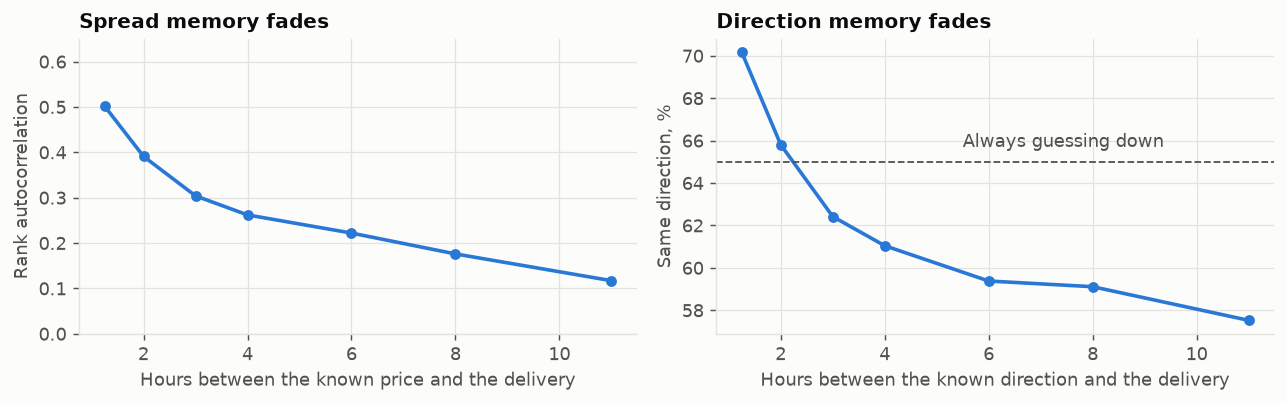

In [10]:
# Chart persistence, excluding the daily lag from the line
shown = persistence[persistence["hours"] <= 11]
figure, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(shown["hours"], shown["rank_autocorrelation"], color=BLUE, marker="o", markersize=5)
axes[0].set_title("Spread memory fades")
axes[0].set_xlabel("Hours between the known price and the delivery")
axes[0].set_ylabel("Rank autocorrelation")
axes[0].set_ylim(0, 0.65)
axes[1].plot(shown["hours"], shown["same_direction_pct"], color=BLUE, marker="o", markersize=5)
axes[1].axhline(max(SUMMARY["down_share_pct"], 100 - SUMMARY["down_share_pct"]), color=MUTED, linewidth=1, linestyle="--")
axes[1].text(5.5, max(SUMMARY["down_share_pct"], 100 - SUMMARY["down_share_pct"]) + 0.7, "Always guessing down", color=MUTED)
axes[1].set_title("Direction memory fades")
axes[1].set_xlabel("Hours between the known direction and the delivery")
axes[1].set_ylabel("Same direction, %")
save(figure, "fig4_persistence.png")

**What we learnt**

- The newest known price is already 1 h 15 old, and its information fades fast. Rank autocorrelation is 0.50 at 1 h 15, 0.30 at 3 h and 0.12 at 11 h.
- The last known direction beats always guessing "down" (65%) only up to about 2 hours ahead.

**Why this helps against the baseline**

The baseline relies entirely on the last known price, so its error grows with the horizon. We combine recent prices with information already published for every step: spot and the day-ahead forecasts.

## 5. System conditions

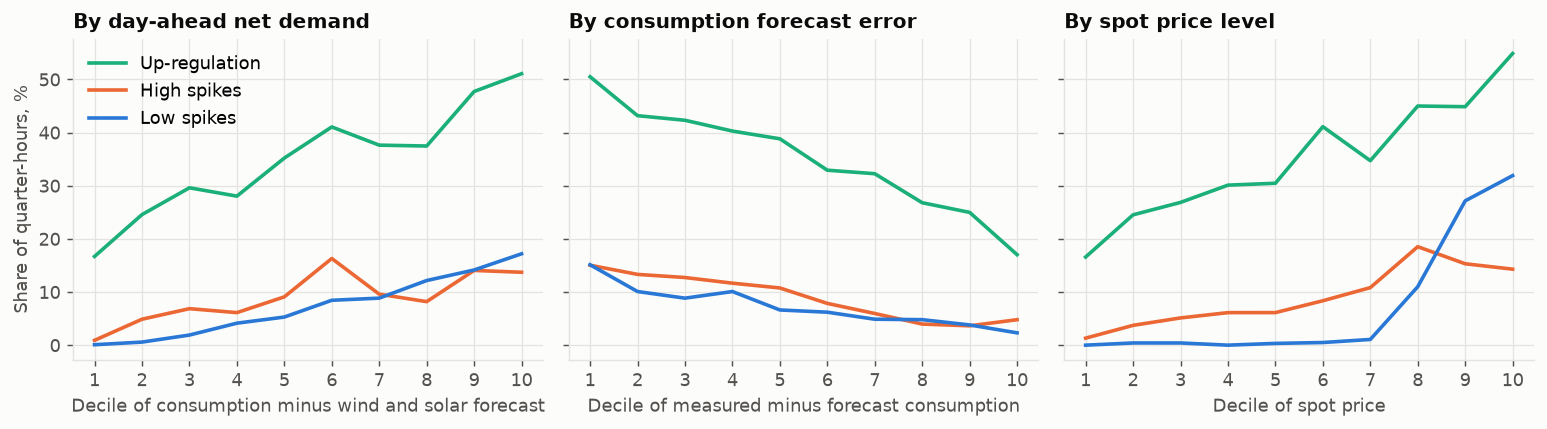

{'net_fc': {'high': [0.9, 9.1, 13.7], 'low': [0.1, 5.3, 17.2], 'up': [16.7, 35.2, 51.1]}, 'cons_err': {'high': [15.0, 10.8, 4.8], 'low': [15.1, 6.6, 2.3], 'up': [50.5, 38.8, 17.0]}, 'fi_spot_price': {'high': [1.3, 6.1, 14.3], 'low': [0.0, 0.3, 31.9], 'up': [16.6, 30.5, 54.9]}}


In [11]:
# Chart spike and direction rates by net demand, consumption error and spot level
table["net_fc"] = table["fi_consumption_fc_da"] - table["fi_wind_fc_da"] - table["fi_solar_fc_da"]
table["cons_err"] = table["fi_consumption"] - table["fi_consumption_fc_da"]
figure, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
SUMMARY["conditions"] = {}
for axis, column, title, label in [
    (axes[0], "net_fc", "By day-ahead net demand", "Decile of consumption minus wind and solar forecast"),
    (axes[1], "cons_err", "By consumption forecast error", "Decile of measured minus forecast consumption"),
    (axes[2], "fi_spot_price", "By spot price level", "Decile of spot price"),
]:
    deciles = pd.qcut(table[column], 10, labels=False) + 1
    rates = table.groupby(deciles)[["high", "low", "up"]].mean() * 100
    axis.plot(rates.index, rates["up"], color=AQUA, label="Up-regulation")
    axis.plot(rates.index, rates["high"], color=ORANGE, label="High spikes")
    axis.plot(rates.index, rates["low"], color=BLUE, label="Low spikes")
    axis.set_title(title)
    axis.set_xlabel(label)
    axis.set_xticks(range(1, 11))
    SUMMARY["conditions"][column] = rates.round(1).reset_index(drop=True).iloc[[0, 4, 9]].to_dict("list")
axes[0].set_ylabel("Share of quarter-hours, %")
axes[0].legend(loc="upper left")
save(figure, "fig5_system_conditions.png")
print(SUMMARY["conditions"])

**What we learnt**

These are associations in the training data, not proven causes.

- **Net demand:** up-regulation rises from 16.7% to 51.1% between the lowest and highest net demand deciles.
- **Spot level:** up-regulation rises from 16.6% to 54.9% across spot deciles.
- **Low spikes need a high spot price:** 0% in the lowest spot decile, 31.9% in the highest. The price needs room to fall 50 EUR/MWh below spot.
- **Consumption below forecast** goes with more up-regulation: 50.5% in the lowest error decile, 17.0% in the highest.

**Why this helps against the baseline**

The baseline uses fixed historical spike and direction rates for every quarter-hour. Our models use spot level, net demand and recent consumption error, so their probabilities rise and fall with conditions.

## 6. Validation results

In [12]:
# Join the validation forecast with its actual values
forecast = pd.read_csv(ARTIFACTS / "validation" / "forecast_validation.csv")
actuals = pd.read_csv(DATA / "actuals_validation.csv")
scored = forecast.merge(actuals, on="delivery_start_utc", how="inner")
scored["spread"] = scored["imbalance_price"] - scored["spot_price"]
scored["error"] = (scored["imbalance_price"] - scored["p50"]).abs()
scored["hour_ahead"] = (scored["step"] - 1) // 4 + 1
scored["width"] = scored["p90"] - scored["p10"]
scored["high"] = (scored["spread"] > 50).astype(int)
scored["low"] = (scored["spread"] < -50).astype(int)
scored["up"] = (scored["direction"] == "up").astype(int)
scored["inside"] = (scored["imbalance_price"] >= scored["p10"]) & (scored["imbalance_price"] <= scored["p90"])
SUMMARY["validation_rows"] = int(len(scored))

In [13]:
# Compare with the official baseline and simple spot benchmarks
history = table[table.index < FOLDS["F3"][0]]
early = known[usable["fi_imbalance_price"] <= FOLDS["F3"][0]]
early_spread = early["fi_imbalance_price"] - early["fi_spot_price"]
median_all = early_spread.median()
median_by_direction = early_spread.groupby(early["fi_mfrr_direction"]).median()
direction_code = scored["direction"].map({"up": 1, "down": -1, "none": 0})
baseline = pd.read_csv(ARTIFACTS / "baseline_score" / "score_summary.csv").iloc[0]
official = pd.read_csv(ARTIFACTS / "validation" / "score" / "score_summary.csv").iloc[0]
SUMMARY["benchmarks"] = {
    "spot_only_mae": round(float((scored["imbalance_price"] - scored["spot_price"]).abs().mean()), 2),
    "spot_plus_median_mae": round(float((scored["imbalance_price"] - scored["spot_price"] - median_all).abs().mean()), 2),
    "oracle_true_direction_mae": round(float((scored["imbalance_price"] - scored["spot_price"] - direction_code.map(median_by_direction)).abs().mean()), 2),
    "baseline": {k: round(float(baseline[k]), 4) for k in ["mae_p50", "calibration_pinball_mean", "coverage_p10_p90", "brier_spike_mean", "brier_direction"]},
    "model": {k: round(float(official[k]), 4) for k in ["mae_p50", "pinball_p10", "pinball_p90", "calibration_pinball_mean", "coverage_p10_p90", "brier_spike_high", "brier_spike_low", "brier_spike_mean", "brier_direction", "observed_spike_high_share", "observed_spike_low_share"]},
}
print(json.dumps(SUMMARY["benchmarks"], indent=1))

{
 "spot_only_mae": 46.61,
 "spot_plus_median_mae": 44.3,
 "oracle_true_direction_mae": 36.5,
 "baseline": {
  "mae_p50": 66.2033,
  "calibration_pinball_mean": 24.1776,
  "coverage_p10_p90": 0.6829,
  "brier_spike_mean": 0.1132,
  "brier_direction": 0.4509
 },
 "model": {
  "mae_p50": 42.2885,
  "pinball_p10": 7.2212,
  "pinball_p90": 16.5961,
  "calibration_pinball_mean": 11.9086,
  "coverage_p10_p90": 0.7901,
  "brier_spike_high": 0.099,
  "brier_spike_low": 0.0854,
  "brier_spike_mean": 0.0922,
  "brier_direction": 0.3987,
  "observed_spike_high_share": 0.1213,
  "observed_spike_low_share": 0.1296
 }
}


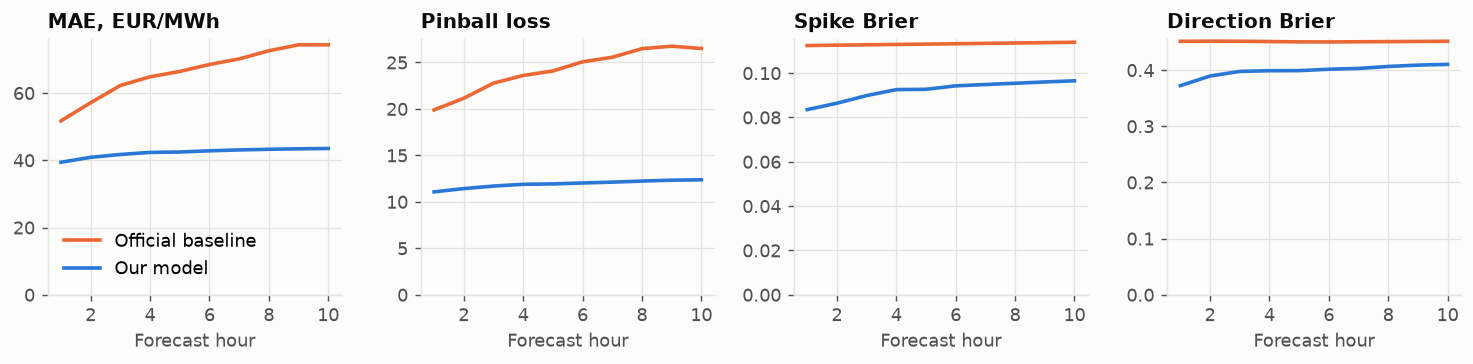

In [14]:
# Chart skill by forecast hour against the official baseline
model_hours = pd.read_csv(ARTIFACTS / "validation" / "score" / "score_by_horizon.csv")
base_hours = pd.read_csv(ARTIFACTS / "baseline_score" / "score_by_horizon.csv")
panels = [("mae_p50", "MAE, EUR/MWh"), ("calibration_pinball_mean", "Pinball loss"), ("brier_spike_mean", "Spike Brier"), ("brier_direction", "Direction Brier")]
figure, axes = plt.subplots(1, 4, figsize=(11.5, 2.9))
for axis, (column, title) in zip(axes, panels):
    axis.plot(base_hours["horizon_hour"], base_hours[column], color=ORANGE, label="Official baseline")
    axis.plot(model_hours["horizon_hour"], model_hours[column], color=BLUE, label="Our model")
    axis.set_title(title)
    axis.set_xlabel("Forecast hour")
    axis.set_ylim(bottom=0)
axes[0].legend(loc="lower left")
save(figure, "fig6_horizon.png")
SUMMARY["baseline_horizon_mae"] = base_hours["mae_p50"].round(1).tolist()
SUMMARY["horizon"] = model_hours[["horizon_hour", "mae_p50", "calibration_pinball_mean", "coverage_p10_p90", "brier_spike_mean", "brier_direction"]].round(3).iloc[[0, 4, 9]].to_dict("records")

**What we learnt**

- Our MAE barely changes over the 10 hours, from 41.3 in hour 1 to 43.6 in hour 10.
- The baseline's MAE grows from 51.7 to 74.4.
- Pinball, spike and direction scores are better than the baseline in every hour.

**Why we did better**

- **The baseline is persistence:** the last known price, which is already 1 h 15 old at step 1, gets older with every step.
- **Our inputs stay fresh for every step:** spot and the day-ahead forecasts are published for the whole 10 hours.
- **We predict the gap to spot,** so the forecast follows spot's daily shape.
- **Our probabilities change with conditions,** while the baseline's spike and direction probabilities are fixed historical shares.

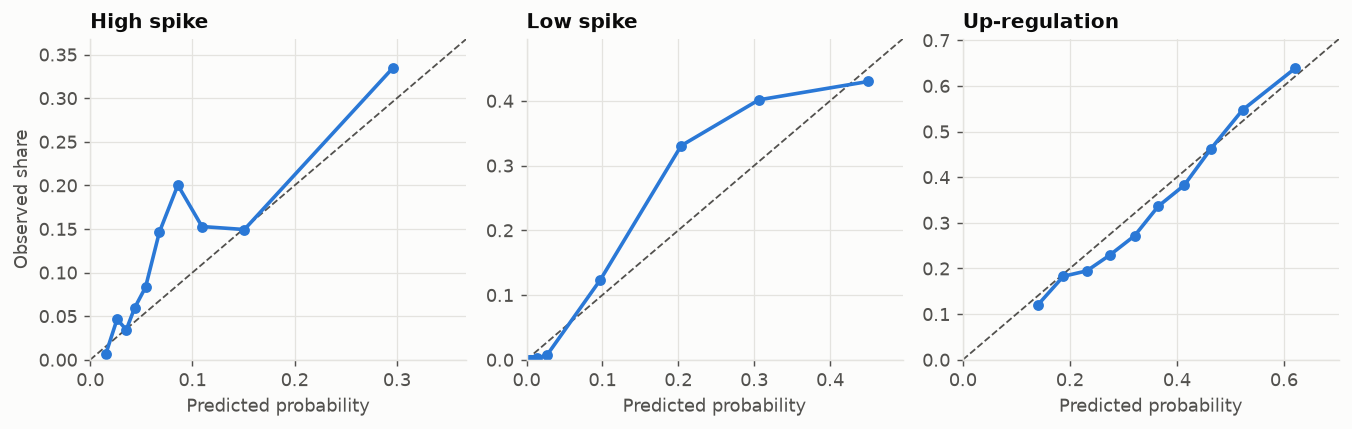

{'high': {'predicted': [0.015, 0.054, 0.296], 'observed': [0.007, 0.083, 0.334]}, 'low': {'predicted': [0.004, 0.014, 0.451], 'observed': [0.0, 0.002, 0.43]}, 'up': {'predicted': [0.14, 0.321, 0.621], 'observed': [0.119, 0.272, 0.639]}}


In [15]:
# Chart reliability of the three main probabilities
figure, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharex=False)
SUMMARY["reliability"] = {}
for axis, column, label, title in [(axes[0], "p_spike_high", "high", "High spike"), (axes[1], "p_spike_low", "low", "Low spike"), (axes[2], "p_up", "up", "Up-regulation")]:
    groups = pd.qcut(scored[column], 10, labels=False, duplicates="drop")
    points = scored.groupby(groups).agg(predicted=(column, "mean"), observed=(label, "mean"))
    limit = max(points.max()) * 1.1
    axis.plot([0, limit], [0, limit], color=MUTED, linewidth=1, linestyle="--")
    axis.plot(points["predicted"], points["observed"], color=BLUE, marker="o", markersize=5)
    axis.set_title(title)
    axis.set_xlabel("Predicted probability")
    axis.set_xlim(0, limit)
    axis.set_ylim(0, limit)
    SUMMARY["reliability"][label] = points.round(3).iloc[[0, 4, -1]].to_dict("list")
axes[0].set_ylabel("Observed share")
save(figure, "fig7_reliability.png")
print(SUMMARY["reliability"])

**What we learnt**

- **Up-regulation:** probabilities are close to the diagonal, so a predicted 60% really happened about 60% of the time.
- **Low spikes:** close to the diagonal.
- **High spikes:** too low in the middle range. Predicted 6% happened 11% of the time, because high spikes were more frequent in September than in the training data.

**Why this helps against the baseline**

The baseline gives the same spike and direction probabilities to every quarter-hour, so it can't separate risky periods from calm ones. Our probabilities rank them, which is what the Brier score rewards.

## 7. Does the model know when it may be wrong?

In [16]:
# Group error by predicted interval width and spike risk
scored["width_group"] = pd.qcut(scored["width"], 5, labels=False) + 1
by_width = scored.groupby("width_group").agg(mean_width=("width", "mean"), mae=("error", "mean"), coverage=("inside", "mean"), large_error_pct=("error", lambda e: 100 * (e > 100).mean())).round(3)
scored["risk"] = scored[["p_spike_high", "p_spike_low"]].max(axis=1)
scored["spike"] = scored["high"] | scored["low"]
thresholds = []
for threshold in [0.15, 0.25, 0.35]:
    for name, column, label in [("high", "p_spike_high", "high"), ("low", "p_spike_low", "low")]:
        hits = scored[scored[column] >= threshold]
        thresholds.append({"type": name, "threshold": threshold, "rows": len(hits), "share_of_rows_pct": round(100 * len(hits) / len(scored), 1), "observed_pct": round(100 * hits[label].mean(), 1) if len(hits) else None, "base_rate_pct": round(100 * scored[label].mean(), 1), "captured_pct": round(100 * hits[label].sum() / scored[label].sum(), 1)})
SUMMARY["by_width"] = by_width.reset_index().to_dict("records")
SUMMARY["alert_precision"] = thresholds
ordered = scored["error"].sort_values(ascending=False)
SUMMARY["worst_1pct_error_share"] = round(float(ordered.iloc[:len(ordered) // 100].sum() / ordered.sum()), 3)
display(by_width)
display(pd.DataFrame(thresholds))

,mean_width,mae,coverage,large_error_pct
width_group,,,,
1,33.031,7.954,0.852,0.000
2,66.718,16.460,0.856,0.861
3,101.414,32.345,0.832,6.386
4,135.841,52.304,0.748,12.397
5,172.710,102.380,0.663,26.610


,type,threshold,rows,share_of_rows_pct,observed_pct,base_rate_pct,captured_pct
0,high,0.15,3932,14.7,27.9,12.1,33.9
1,low,0.15,8078,30.3,38.6,13.0,90.2
2,high,0.25,1396,5.2,42.6,12.1,18.4
3,low,0.25,5392,20.2,41.5,13.0,64.6
4,high,0.35,698,2.6,55.7,12.1,12.0
5,low,0.35,2996,11.2,42.3,13.0,36.6


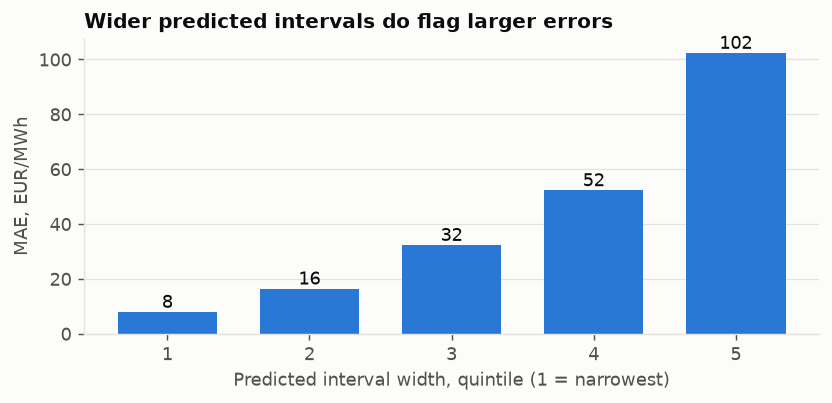

In [17]:
# Chart error against predicted interval width
figure, axis = plt.subplots(figsize=(6.5, 3.2))
axis.bar(by_width.index, by_width["mae"], color=BLUE, width=0.7)
for x, y in zip(by_width.index, by_width["mae"]):
    axis.text(x, y + 1.5, f"{y:.0f}", ha="center", color=INK)
axis.set_title("Wider predicted intervals do flag larger errors")
axis.set_xlabel("Predicted interval width, quintile (1 = narrowest)")
axis.set_ylabel("MAE, EUR/MWh")
axis.grid(axis="x", visible=False)
save(figure, "fig8_error_by_width.png")

**What we learnt**

- The predicted range width is a useful warning. MAE rises from 8 EUR/MWh in the narrowest fifth of ranges to 103 in the widest.
- Coverage drops from 87% to 66% in the widest group, so ranges are still too narrow when conditions are most volatile.

**Why it matters**

The brief asks for a solution that recognises when the error may be large. A wide range tells the user to treat that forecast with care, which the baseline can only do through its fixed per-step widths.

## 8. What drives the models

In [18]:
# Fit the validation-fold models and measure SHAP importance by feature group
rows = attach_labels(build_features(values, usable, all_origins()), values, usable)
cutoff, end = FOLDS["F3"]
train = rows[(rows["label_fu"] <= cutoff) & rows["y_price"].notna()]
check = rows[(rows["origin"] >= cutoff) & (rows["origin"] < end)]
models = fit_all(train)
GROUPS = {
    "Day-ahead price shape": ["spot", "spot_dev_day", "spot_drange", "spot_chg_prev_h"],
    "System forecast": ["net_fc", "wind_fc", "cons_fc", "net_ramp_prev_h"],
    "Calendar and horizon": ["hour", "is_weekend", "step"],
    "Recent price": ["sp_last", "sp_med_4h", "sp_med_24h", "gap_h", "sp_last_decay", "sp_mix"],
    "Recent balancing": ["dir_last", "up_6h", "up_24h", "mfrr_up_prem_4h", "mfrr_dn_prem_4h", "afrr_up_prem_4h", "afrr_dn_prem_4h"],
    "Fresh system state": ["cons_err_1h", "net_export"],
    "Volatility regime": ["abs_med_24h", "abs_med_72h", "hi_72h", "lo_72h"],
}
importance = {}
top_features = {}


# Average SHAP contributions of a classifier group over its step buckets and layouts
def classifier_contributions(group, features):
    total = np.zeros((len(check), len(features)))
    for model in models["classifiers"]:
        mask = in_bucket(check, model["low"], model["high"])
        total[mask] += np.mean([m.predict(check.loc[mask, features], pred_contrib=True)[:, :-1] for m in model[group]], axis=0)
    return total / len(CLASS_LAYOUTS)


for name, contributions, features in [("Price (p50)", p50_contributions(models, check), DRIVER_FEATURES),
                                      ("High spike", classifier_contributions("spike_high", SPIKE_FEATURES), SPIKE_FEATURES),
                                      ("Low spike", classifier_contributions("spike_low", SPIKE_FEATURES), SPIKE_FEATURES),
                                      ("Up-regulation", classifier_contributions("up_l4", CORE), CORE)]:
    by_feature = pd.Series(np.abs(contributions).mean(axis=0), index=features)
    importance[name] = {label: 100 * by_feature.reindex(members).fillna(0).sum() / by_feature.sum() for label, members in GROUPS.items()}
    top_features[name] = by_feature.sort_values(ascending=False).head(6).round(3).to_dict()
importance = pd.DataFrame(importance)
SUMMARY["importance_pct"] = importance.round(1).to_dict()
SUMMARY["top_features"] = top_features
display(importance.round(1))
print(json.dumps(top_features, indent=1))

,Price (p50),High spike,Low spike,Up-regulation
Day-ahead price shape,25.6,34.9,63.5,43.5
System forecast,9.2,10.5,3.9,11.6
Calendar and horizon,6.6,10.0,1.7,9.7
Recent price,25.4,13.0,9.6,22.3
Recent balancing,24.5,13.0,7.9,9.7
Fresh system state,8.7,0.4,1.5,3.2
Volatility regime,0.0,18.2,11.8,0.0


{
 "Price (p50)": {
  "spot": 3.979,
  "sp_last": 2.933,
  "net_export": 1.807,
  "sp_med_24h": 1.708,
  "mfrr_dn_prem_4h": 1.684,
  "afrr_up_prem_4h": 1.392
 },
 "High spike": {
  "spot_drange": 0.553,
  "wind_fc": 0.18,
  "sp_last": 0.178,
  "lo_72h": 0.156,
  "spot": 0.14,
  "is_weekend": 0.135
 },
 "Low spike": {
  "spot": 1.218,
  "spot_drange": 0.296,
  "spot_dev_day": 0.213,
  "abs_med_24h": 0.145,
  "sp_med_4h": 0.12,
  "sp_last": 0.091
 },
 "Up-regulation": {
  "spot_dev_day": 0.251,
  "spot_drange": 0.156,
  "sp_last": 0.133,
  "spot": 0.129,
  "is_weekend": 0.089,
  "sp_med_4h": 0.076
 }
}


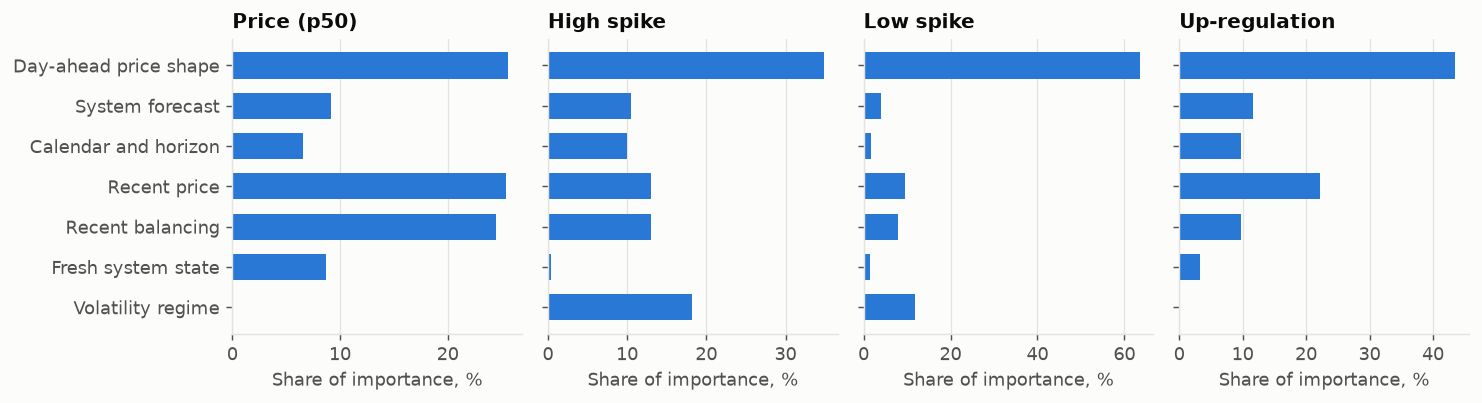

In [19]:
# Chart each model's share of SHAP importance by feature group
figure, axes = plt.subplots(1, 4, figsize=(11.5, 3.2), sharey=True)
order = list(GROUPS)[::-1]
for axis, column in zip(axes, importance.columns):
    axis.barh(order, importance.loc[order, column], color=BLUE, height=0.65)
    axis.set_title(column)
    axis.set_xlabel("Share of importance, %")
    axis.grid(axis="y", visible=False)
save(figure, "fig9_drivers.png")

**What we learnt**

SHAP explains what the model uses. It doesn't prove causes.

- **Price:** the day-ahead price shape (26%), recent price state (25%) and recent balancing (25%) matter about equally.
- **Spikes:** the day-ahead price shape dominates, at 35% for high spikes and 64% for low spikes.
- **Direction:** the price shape leads at 44%.
- **Volatility features** matter only in the spike models (18% and 12%). The other models don't use them.
- **Fresh system data** matters only for price (9%).

**Why this helps against the baseline**

The baseline uses only the last price. Our models combine the published price shape, system forecasts, calendar and recent market state, and each forecast row lists its three main drivers in `top_drivers`.

## 9. Case studies

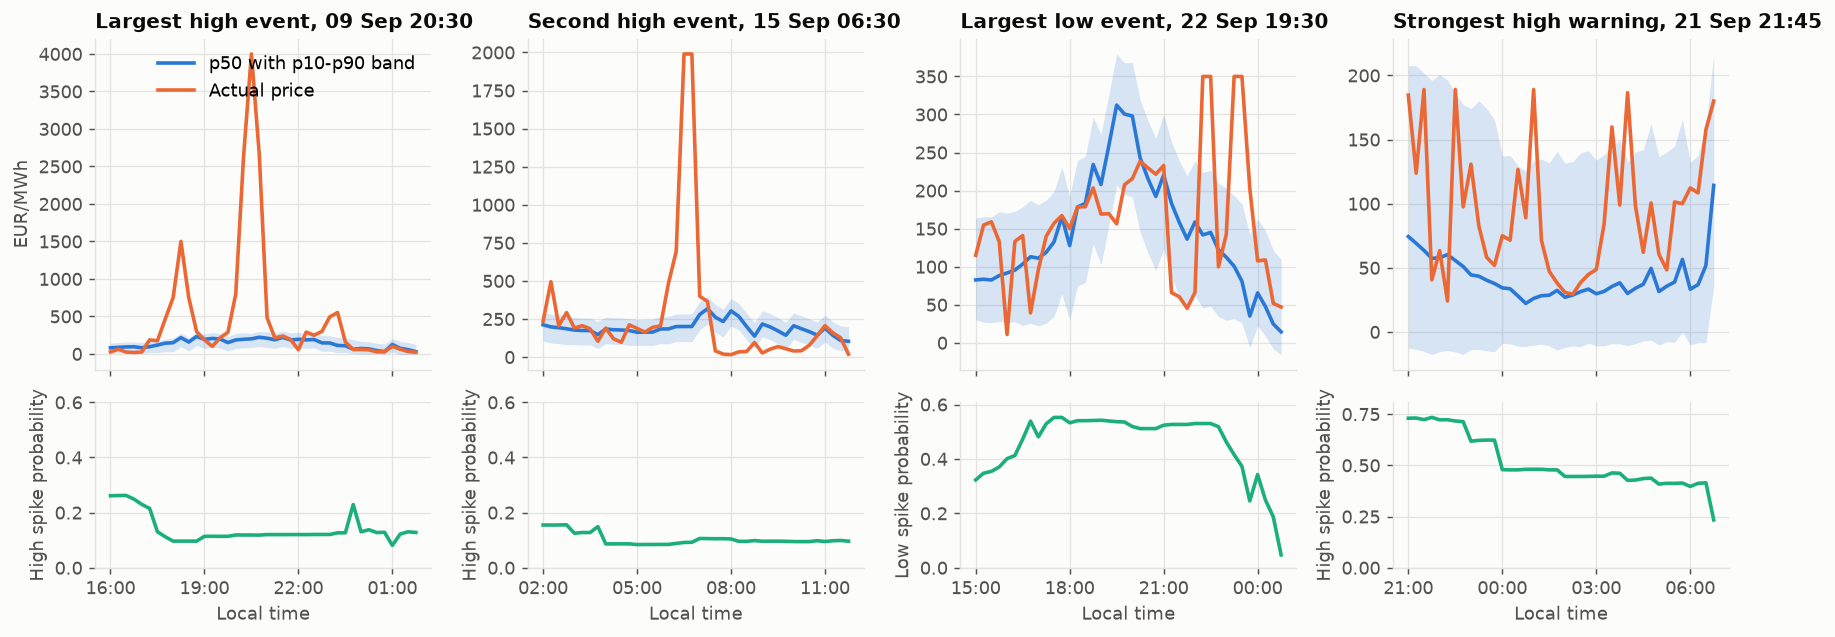

[
 {
  "label": "Largest high event",
  "kind": "High",
  "local_time": "2026-09-09 20:30",
  "origin_local": "2026-09-09 16:00",
  "actual_price": 4000.0,
  "p10": 85.655,
  "p50": 201.158,
  "p90": 276.033,
  "probability": 0.118723,
  "window_mean_probability": 0.14,
  "window_observed_share": 0.45,
  "base_rate": 0.121,
  "p_up": 0.691589,
  "drivers": "spot;sp_last;net_fc",
  "inside_interval": false
 },
 {
  "label": "Second high event",
  "kind": "High",
  "local_time": "2026-09-15 06:30",
  "origin_local": "2026-09-15 02:00",
  "actual_price": 1990.0,
  "p10": 101.666,
  "p50": 200.751,
  "p90": 283.382,
  "probability": 0.091699,
  "window_mean_probability": 0.104,
  "window_observed_share": 0.175,
  "base_rate": 0.121,
  "p_up": 0.562461,
  "drivers": "spot;sp_last;mfrr_dn_prem_4h",
  "inside_interval": false
 },
 {
  "label": "Largest low event",
  "kind": "Low",
  "local_time": "2026-09-22 19:30",
  "origin_local": "2026-09-22 15:00",
  "actual_price": 156.3,
  "p10": 207.0

In [20]:
# Pick the largest high and low events at least two days apart
scored_actuals = actuals.copy()
scored_actuals["spread"] = scored_actuals["imbalance_price"] - scored_actuals["spot_price"]
scored_actuals["time"] = pd.to_datetime(scored_actuals["delivery_start_utc"], utc=True)


# Return the largest events in order, skipping any too close to one already picked
def pick(frame, count):
    chosen = []
    for _, row in frame.iterrows():
        if all(abs((row["time"] - other).total_seconds()) > 2 * 86400 for other in chosen):
            chosen.append(row["time"])
        if len(chosen) == count:
            break
    return chosen


high_events = pick(scored_actuals.sort_values("spread", ascending=False), 2)
low_candidates = scored_actuals[scored_actuals["time"].apply(lambda t: all(abs((t - other).total_seconds()) > 2 * 86400 for other in high_events))]
low_events = pick(low_candidates.sort_values("spread"), 1)
scored["origin_time"] = pd.to_datetime(scored["forecast_origin_utc"], utc=True)
scored["delivery_time"] = pd.to_datetime(scored["delivery_start_utc"], utc=True)

# Add the origin where the model gave its strongest high-spike warning over 10 hours
strongest_origin = scored.groupby("origin_time")["p_spike_high"].mean().idxmax()
strongest_view = scored[scored["origin_time"] == strongest_origin]
strongest_moment = strongest_view.loc[strongest_view["p_spike_high"].idxmax(), "delivery_time"]
events = [("High", t, "Largest high event") for t in high_events[:1]] + [("High", high_events[1], "Second high event")] + [("Low", low_events[0], "Largest low event")] + [("High", strongest_moment, "Strongest high warning")]

# Chart each event as seen from its origin, in local time
figure, axes = plt.subplots(2, 4, figsize=(13.5, 5), sharex="col", gridspec_kw={"height_ratios": [2, 1]})
SUMMARY["cases"] = []
for index, (kind, moment, label) in enumerate(events):
    origin = strongest_origin if label == "Strongest high warning" else moment.floor("h") - pd.Timedelta(hours=4)
    view = scored[scored["origin_time"] == origin].sort_values("delivery_time")
    hit = view[view["delivery_time"] == moment].iloc[0]
    times = view["delivery_time"].dt.tz_convert("Europe/Helsinki").dt.tz_localize(None)
    axes[0, index].fill_between(times, view["p10"], view["p90"], color=BLUE, alpha=0.18, linewidth=0)
    axes[0, index].plot(times, view["p50"], color=BLUE, label="p50 with p10-p90 band")
    axes[0, index].plot(times, view["imbalance_price"], color=ORANGE, label="Actual price")
    axes[0, index].set_title(f"{label}, {moment.tz_convert('Europe/Helsinki'):%d %b %H:%M}")
    probability = "p_spike_high" if kind == "High" else "p_spike_low"
    axes[1, index].plot(times, view[probability], color=AQUA)
    axes[1, index].set_ylim(0, max(0.6, view[probability].max() * 1.1))
    axes[1, index].set_xlabel("Local time")
    axes[1, index].xaxis.set_major_locator(HourLocator(interval=3))
    axes[1, index].xaxis.set_major_formatter(DateFormatter("%H:%M"))
    axes[1, index].set_ylabel(f"{kind} spike probability")
    actual_spikes = view["high" if kind == "High" else "low"]
    SUMMARY["cases"].append({
        "label": label, "kind": kind, "local_time": f"{moment.tz_convert('Europe/Helsinki'):%Y-%m-%d %H:%M}", "origin_local": f"{origin.tz_convert('Europe/Helsinki'):%Y-%m-%d %H:%M}",
        "actual_price": round(float(hit["imbalance_price"]), 1), "p10": float(hit["p10"]), "p50": float(hit["p50"]), "p90": float(hit["p90"]),
        "probability": float(hit[probability]), "window_mean_probability": round(float(view[probability].mean()), 3), "window_observed_share": round(float(actual_spikes.mean()), 3), "base_rate": round(float(scored["high" if kind == "High" else "low"].mean()), 3),
        "p_up": float(hit["p_up"]), "drivers": hit["top_drivers"], "inside_interval": bool(hit["inside"]),
    })
axes[0, 0].set_ylabel("EUR/MWh")
axes[0, 0].legend(loc="upper right")
save(figure, "fig10_case_studies.png")
print(json.dumps(SUMMARY["cases"], indent=1))

**What we learnt**

| Case | Result |
|---|---|
| Largest high event, 9 Sep (4,000 EUR/MWh) | **Missed.** Spike risk 13%, close to the 12% average |
| Second high event, 15 Sep (1,990 EUR/MWh) | **Missed** |
| Largest low event, 22 Sep | **Flagged.** Low-spike risk 52% against a 13% average. 35% of that window's quarter-hours were low spikes |
| Strongest high warning, 21 Sep | **Risk flagged, price level not.** Spike risk was 61% and the price reached 730, while `p50` stayed at 37 |

**What it means for users**

- The largest spikes aren't predictable from this data. Their triggers, such as unplanned outages, aren't in the package.
- Read the spike probabilities together with `p50`. In the last case the price forecast stayed low, while the risk warning was right.
- The baseline would have shown the last known price and the same fixed spike rate in every one of these cases.

In [21]:
# Save every measured value for the report
(ROOT / "docs" / "eda_summary.json").write_text(json.dumps(SUMMARY, indent=1, default=str))

10060